# 02 · Preprocessing & Feature Engineering
**Project:** E-Commerce Product Return Prediction
**Goal:** turn the raw data into model-ready data (everything *before* `model.fit()`).
**Steps:** clean → engineer features → split → encode & scale (pipeline) → save

**Input:** `train.csv`  |  **Output:** `features.py`, `preprocessor.joblib`, `processed_data.joblib`

## 1. Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42

df = pd.read_csv('train.csv')
print('Shape:', df.shape)

Shape: (200000, 16)


## 2. Reusable Cleaning & Feature Functions
We write the cleaning and feature code into **`features.py`**, so the **same code** can later be reused in the FastAPI app (no mismatch between training and prediction).

In [2]:
%%writefile features.py
import numpy as np
import pandas as pd

def clean(df):
    """Remove ID and turn impossible values into NaN (imputed later in the pipeline)."""
    df = df.copy()
    df = df.drop(columns=['order_id'], errors='ignore')
    df.loc[df['product_price'] <= 0, 'product_price'] = np.nan
    df.loc[df['num_product_views'] < 0, 'num_product_views'] = np.nan
    df.loc[df['session_length_minutes'] < 0, 'session_length_minutes'] = np.nan
    df['product_rating'] = df['product_rating'].clip(upper=5)   # rating scale is 0-5
    return df

def add_features(df):
    """Create new features from existing columns."""
    df = df.copy()
    df['is_late_delivery']     = (df['delivery_delay_days'] > 0).astype(int)
    df['price_after_discount'] = df['product_price'] * (1 - df['discount_percent'] / 100)
    df['log_price']            = np.log1p(df['product_price'])
    df['views_per_minute']     = df['num_product_views'] / (df['session_length_minutes'] + 1)
    df['expected_returns']     = df['past_purchase_count'] * df['past_return_rate']
    df['high_return_customer'] = (df['past_return_rate'] > 0.30).astype(int)
    df['age_group'] = pd.cut(df['customer_age'], bins=[0, 25, 40, 60, 120],
                             labels=['<=25', '26-40', '41-60', '60+']).astype(str)
    return df

Overwriting features.py


In [4]:
from features import clean, add_features
print('Functions imported')

Functions imported


## 3. Cleaning

In [5]:
raw = pd.read_csv('train.csv')
clean_df = clean(raw)

before = pd.Series({'price <= 0': (raw.product_price <= 0).sum(),
                    'views < 0': (raw.num_product_views < 0).sum(),
                    'session < 0': (raw.session_length_minutes < 0).sum(),
                    'rating > 5': (raw.product_rating > 5).sum()})
after = clean_df.isna().sum()[['product_price', 'num_product_views', 'session_length_minutes']]
print('Impossible values found (before):'); display(before.to_frame('rows'))
print('NaN created (after):'); display(after.to_frame('NaN'))
print('Max rating now:', clean_df.product_rating.max(), '| Columns:', clean_df.shape[1])

Impossible values found (before):


,rows
price <= 0,27285
views < 0,21443
session < 0,1487
rating > 5,3831


NaN created (after):


,NaN
product_price,27285
num_product_views,21443
session_length_minutes,1487


Max rating now: 5.0 | Columns: 15


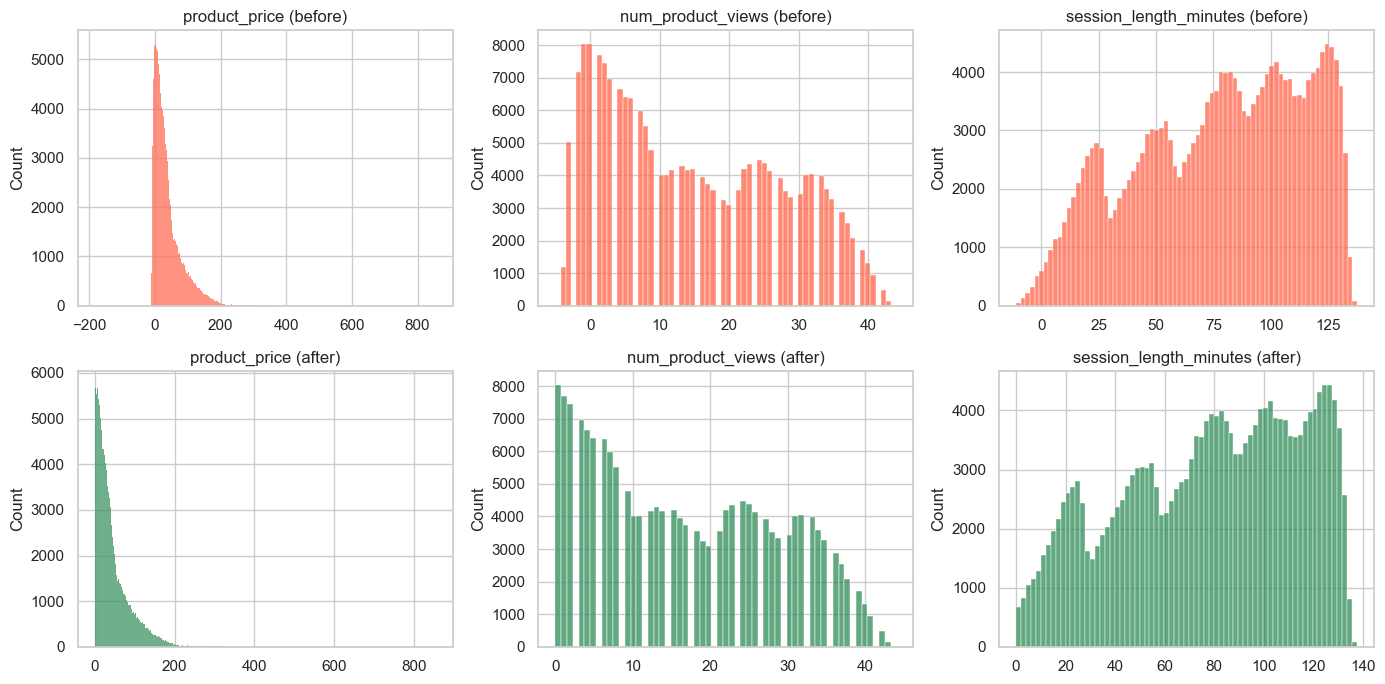

In [6]:
# Before vs after for the columns that were fixed
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, c in enumerate(['product_price', 'num_product_views', 'session_length_minutes']):
    sns.histplot(raw[c], ax=axes[0, j], color='tomato'); axes[0, j].set_title(f'{c} (before)')
    sns.histplot(clean_df[c].dropna(), ax=axes[1, j], color='seagreen'); axes[1, j].set_title(f'{c} (after)')
    axes[0, j].set_xlabel(''); axes[1, j].set_xlabel('')
plt.tight_layout(); plt.show()

**Interpretation**
- Impossible values are now NaN, so negative prices / views / session times are gone from the plots.
- The NaNs are **not filled yet**. We fill them inside the pipeline (Section 6) using the median from the *training data only*, to avoid data leakage.
- `order_id` was dropped.

## 4. Feature Engineering

In [7]:
fe_df = add_features(clean_df)
new_feats = ['is_late_delivery', 'price_after_discount', 'log_price', 'views_per_minute',
             'expected_returns', 'high_return_customer', 'age_group']
fe_df[new_feats].head()

,is_late_delivery,price_after_discount,log_price,views_per_minute,expected_returns,high_return_customer,age_group
0,0,6.584414,2.538932,6.084677,2.651262,1,<=25
1,1,10.503783,3.477509,0.060830,0.946828,0,60+
2,1,20.174377,3.275657,NaN,3.313558,0,26-40
3,1,10.047412,2.675332,0.067305,3.690341,1,60+
4,0,64.005596,4.340831,0.058967,1.112083,0,41-60


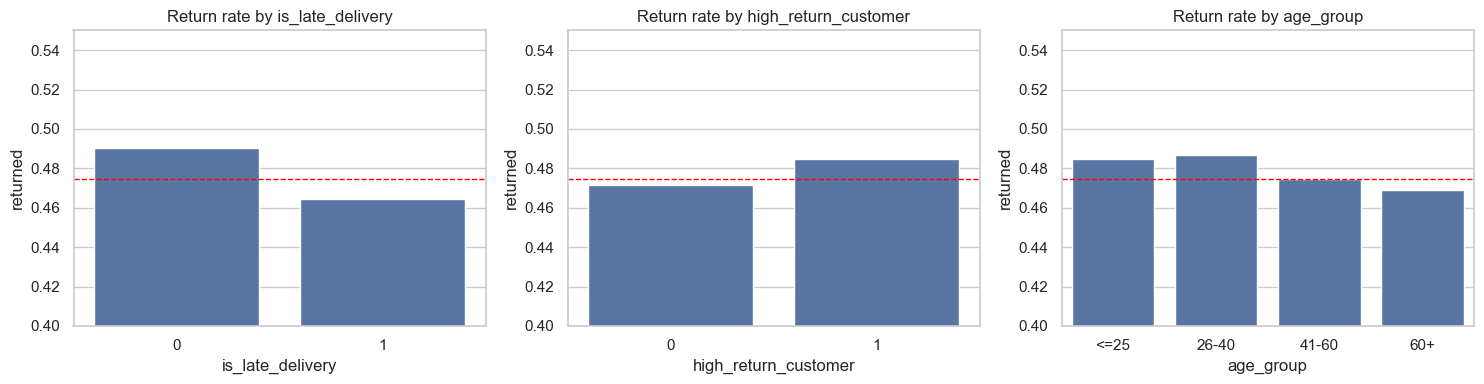

In [8]:
# Do the new features relate to returns?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['is_late_delivery', 'high_return_customer', 'age_group']):
    order = ['<=25', '26-40', '41-60', '60+'] if c == 'age_group' else None
    sns.barplot(x=c, y='returned', data=fe_df, order=order, ax=ax, errorbar=None)
    ax.axhline(fe_df.returned.mean(), color='red', ls='--', lw=1)
    ax.set_ylim(0.4, 0.55); ax.set_title(f'Return rate by {c}')
plt.tight_layout(); plt.show()

**Interpretation**
- `high_return_customer` behaves as expected (higher return rate: ~48.5% vs ~47%).
- Surprisingly, **late deliveries have a slightly *lower* return rate** (~46.5% vs ~49%), so delay does not push customers to return.
- `age_group` shows almost no difference, so it is probably a weak feature.
- The real value will be tested later in model comparison (notebook 03), since the proposal plans "Model re-comparison" after feature engineering.

## 5. Train / Test Split

Train: (160000, 21) | Test: (40000, 21)


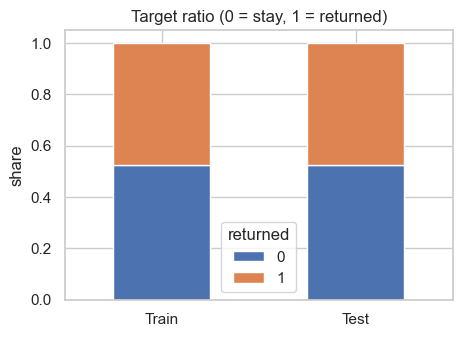

In [9]:
X = fe_df.drop(columns='returned')
y = fe_df['returned']

# Stratified: keeps the same return ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)

ratio = pd.DataFrame({'Train': y_train.value_counts(normalize=True),
                      'Test':  y_test.value_counts(normalize=True)})
ratio.T.plot(kind='bar', stacked=True, figsize=(5, 3.5), rot=0)
plt.title('Target ratio (0 = stay, 1 = returned)'); plt.ylabel('share'); plt.show()

**Interpretation**
- 160,000 training rows and 40,000 test rows, with the **same class ratio** in both.
- We split *before* imputing and scaling, so the test set stays completely unseen (no leakage).

## 6. Preprocessing Pipeline (Impute + Scale + Encode)

In [10]:
cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method', 'age_group']
binary_cols = ['used_coupon', 'is_late_delivery', 'high_return_customer']
num_cols = [c for c in X_train.columns if c not in cat_cols + binary_cols]
print('Numeric:', num_cols)

numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),   # fill NaN with the median
    ('scale',  StandardScaler())])                  # mean = 0, std = 1

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('bin', 'passthrough', binary_cols)])
preprocessor.set_output(transform='pandas')

Numeric: ['customer_age', 'product_price', 'discount_percent', 'product_rating', 'past_purchase_count', 'past_return_rate', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'price_after_discount', 'log_price', 'views_per_minute', 'expected_returns']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

In [11]:
# Fit on TRAIN only, then transform both
X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)
X_train_p.columns = [c.split('__')[-1] for c in X_train_p.columns]
X_test_p.columns  = X_train_p.columns

print('Before:', X_train.shape, '-> After:', X_train_p.shape)
print('Any NaN left? ', X_train_p.isna().sum().sum() + X_test_p.isna().sum().sum())
X_train_p.head()

Before: (160000, 21) -> After: (160000, 36)
Any NaN left?  0


,customer_age,product_price,discount_percent,product_rating,past_purchase_count,past_return_rate,delivery_delay_days,session_length_minutes,num_product_views,price_after_discount,...,payment_method_credit_card,payment_method_debit_card,payment_method_paypal,age_group_26-40,age_group_41-60,age_group_60+,age_group_<=25,used_coupon,is_late_delivery,high_return_customer
34143,0.974661,-0.490607,-0.543741,-0.521905,-0.196909,-0.342190,0.678864,0.568292,-0.927420,-0.338878,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1,0
156471,-0.305650,-0.291461,-0.609707,0.884436,-0.515345,-0.820917,-1.198954,-1.586433,-0.927420,-0.307137,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,0,0
127850,1.030327,-0.263289,-2.330974,-1.259276,-0.196909,-0.005113,1.690867,0.763641,-1.193294,0.322598,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1,1,0
13901,0.195341,-0.684502,-0.534203,-1.000120,-0.833781,-0.884936,-0.215301,-1.827900,-1.193294,-0.539981,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1,1,0
149382,-2.253951,-0.978375,-1.520725,0.334911,-0.515345,-0.712063,-0.302919,-0.649813,-0.838795,-0.834363,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0,0,0


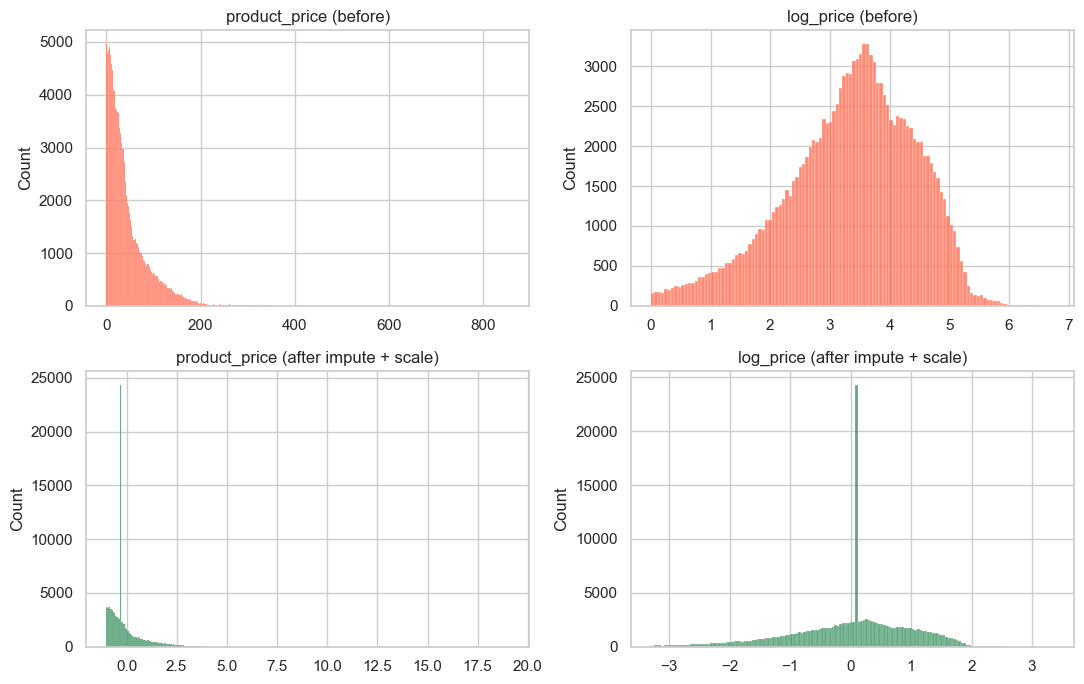

In [12]:
# Scaling effect on skewed features
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, c in enumerate(['product_price', 'log_price']):
    sns.histplot(X_train[c].dropna(), ax=axes[0, j], color='tomato'); axes[0, j].set_title(f'{c} (before)')
    sns.histplot(X_train_p[c], ax=axes[1, j], color='seagreen');      axes[1, j].set_title(f'{c} (after impute + scale)')
    axes[0, j].set_xlabel(''); axes[1, j].set_xlabel('')
plt.tight_layout(); plt.show()

**Interpretation**
- Numeric columns now have mean 0 and std 1, and no NaN remains.
- Categorical columns became 0/1 columns (one-hot), so the data is fully numeric and ready for any scikit-learn model.
- `log_price` is far less skewed than `product_price`.
- The pipeline is **fitted on train only** and reused on test (and later in FastAPI).

## 7. Quick Feature Importance Preview

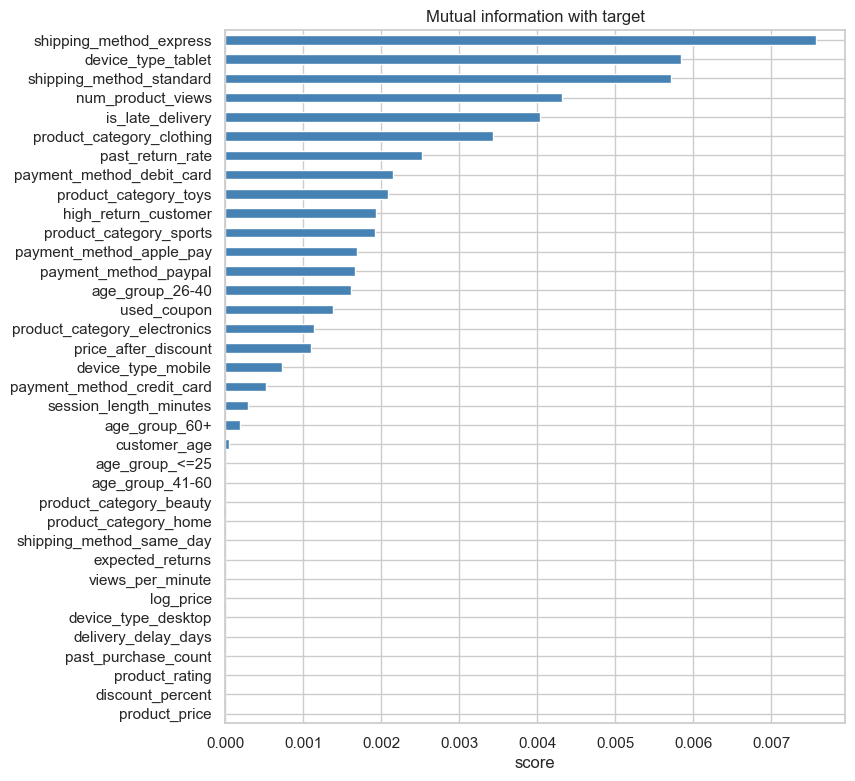

In [13]:
# Mutual information: how much does each feature tell about 'returned'? (sample for speed)
idx = X_train_p.sample(30000, random_state=RANDOM_STATE).index
mi = mutual_info_classif(X_train_p.loc[idx], y_train.loc[idx], random_state=RANDOM_STATE)
mi = pd.Series(mi, index=X_train_p.columns).sort_values()

mi.plot(kind='barh', figsize=(8, 9), color='steelblue')
plt.title('Mutual information with target'); plt.xlabel('score'); plt.show()

**Interpretation**
- Features at the top share the most information with `returned`. Bars near zero add little alone, but may help in combinations.
- This is only a preview. The real ranking comes later from model-based importance and **SHAP** (notebook 03).

## 8. Save Outputs

In [14]:
joblib.dump(preprocessor, 'preprocessor.joblib')
joblib.dump({'X_train': X_train_p, 'X_test': X_test_p,
             'y_train': y_train, 'y_test': y_test}, 'processed_data.joblib')
print('Saved: preprocessor.joblib, processed_data.joblib, features.py')

Saved: preprocessor.joblib, processed_data.joblib, features.py


## 9. Summary
| Step | Done |
|---|---|
| Dropped `order_id` | ✅ |
| Fixed impossible values (to NaN, then median) | ✅ |
| Created 7 new features | ✅ |
| Stratified 80/20 split | ✅ |
| Impute + scale + one-hot pipeline (train-only fit) | ✅ |
| Saved pipeline and data | ✅ |

➡️ Next: **`03_modeling.ipynb`** → load `processed_data.joblib` and start with `model.fit()`